### Agentic Rag With LANGGRAPH

In [1]:
import os
from typing import TypedDict, List
from langgraph.graph import StateGraph, END
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document

C:\Users\vishu\AppData\Local\Temp\ipykernel_25680\549605448.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


In [2]:
import os
from dotenv import load_dotenv
from langchain_anthropic import ChatAnthropic
from langchain_huggingface import HuggingFaceEmbeddings
load_dotenv()

True

In [3]:

llm = ChatAnthropic(
    model="claude-sonnet-4-5",
    temperature=0,
    max_tokens=1024
)

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

C:\Users\vishu\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 816.05it/s]


In [4]:
llm

ChatAnthropic(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.3', 'langchain-anthropic': '1.7.7'}}, profile={'name': 'Claude Sonnet 4.5 (latest)', 'release_date': '2025-09-29', 'last_updated': '2025-09-29', 'open_weights': False, 'max_input_tokens': 200000, 'max_output_tokens': 64000, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_call_streaming': True}, model='claude-sonnet-4-5', max_tokens=1024, temperature=0.0, anthropic_api_url='https://api.anthropic.com', anthropic_api_key=SecretStr('**********'), model_kwargs={})

### State defination

In [5]:
class AgentState(TypedDict):
    question: str
    documents: List[Document]
    answer: str
    needs_retrieval: bool

### Sample documents and vectore store
### sample documentations for demonstration

In [6]:
sample_texts=["RAG: An AI framework that connects a language model to an external data source to generate accurate, factual, and up-to-date responses.",
" Vector Database: A specialized storage engine that saves data as mathematical coordinates to allow fast searches based on context and meaning rather than exact keywords.",
"Agentic System: An AI architecture where the model is given tools, memory, and the autonomy to make its own decisions to complete a multi-step task.",
"Agentic RAG: An advanced retrieval system where an AI agent dynamically controls the search process, evaluating data quality and self-correcting if the results are poor.",
"LangGraph: A developer framework used to build complex, looping AI systems by structuring agent behaviors as nodes (actions) and edges (decisions)."
]

documents=[Document(page_content=text) for text in sample_texts]

### Create vector store

In [7]:
vectorestore= FAISS.from_documents (documents,embeddings)
retriever= vectorestore.as_retriever(k=3)

### Agents Function

In [8]:
def decide_retrieval(state:AgentState) -> AgentState:
    """
    Decide if we need to retrieve documents based on the question
    """

    question = state["question"]

    retrieval_keywords = ["what","why","describe","explain","tell me","how"]
    needs_retrieval= any(keyword in question.lower() for keyword in retrieval_keywords)

    return {**state,"needs_retrieval":needs_retrieval}

In [9]:
def retrieve_document (state:AgentState) -> AgentState:
    """
    Retrieve documents based on the question
    """

    question = state["question"]
    documents= retriever.invoke(question)

    return {**state,"documents":documents}

In [10]:
def generate_answer (state:AgentState) -> AgentState:
    """
    Generate answered based on retrieve documents
    """

    question = state["question"]
    documents= state.get("documents",[])

    if documents:
        context= "\n\n".join([doc.page_content for doc in documents])
        prompt=f"""based on the following context,answer the question:
        
Context:
{context}

Question:
{question}

Answer :"""
    else:
        prompt=f"Answer the following question:{question}"

    response=llm.invoke(prompt)
    answer=response.content

    return {**state,"answer":answer}

### Conditional logic


In [11]:
def should_retrieve(state:AgentState) -> str:
    """
    Determine the next step based on th retrieval
    """

    if state["needs_retrieval"]:
        return "retrieve"
    else:
        return "generate"

### Build the graph

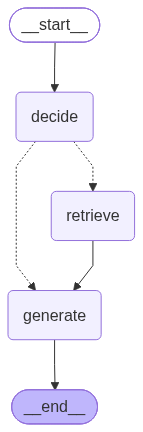

In [12]:
# Create the state graph
workflow = StateGraph(AgentState)

# Add nodes
workflow.add_node("decide", decide_retrieval)
workflow.add_node("retrieve", retrieve_document)
workflow.add_node("generate", generate_answer)

# Set entry point
workflow.set_entry_point("decide")

# Add conditional edges
workflow.add_conditional_edges(
    "decide",
    should_retrieve,
    {
        "retrieve": "retrieve",
        "generate": "generate"
    }
)

# Add edges
workflow.add_edge("retrieve", "generate")
workflow.add_edge("generate", END)

# Compile the graph
app = workflow.compile()
app

### Test the agentic System

In [13]:
def ask_question(question: str):
    """
    Helper function to ask a question and get an answer
    """
    initial_state = {
        "question": question,
        "documents": [],
        "answer": " ",
        "needs_retrieval": False
    }
    
    result = app.invoke(initial_state)
    return result

In [14]:
# Test with a question that should trigger retrieval
question1 = "What is LangGraph ?"
result1 = ask_question(question1)
result1

AnthropicAuthenticationError: Error code: 401 - {'type': 'error', 'error': {'type': 'authentication_error', 'message': 'invalid x-api-key'}, 'request_id': 'req_011CgeTSVUUK86gwqgJGJ3nR'}

In [ ]:
# Test with another question
question2 = "How does RAG work?"
result2 = ask_question(question2)

print(f"Question: {question2}")
print(f"Retrieved documents: {len(result2['documents'])}")
print(f"Answer: {result2['answer']}")
print("\n" + "="*50 + "\n")

AnthropicAuthenticationError: Error code: 401 - {'type': 'error', 'error': {'type': 'authentication_error', 'message': 'invalid x-api-key'}, 'request_id': 'req_011CgZNik1w2kPSx7Hu4BaN4'}